# Segmentation d'image

In [1]:
import numpy as np
import skimage.io as io
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from skimage.filters import threshold_otsu
from skimage.morphology import binary_erosion
from skimage.measure import label

# Vérité terrain
gt = io.imread('parking-vt.png')

In [2]:
# Affichage image, vérité terrain et histogramme
def myshow(img, gt, seg, threshold, threshold_text, color):
    
    fig, axs = plt.subplots(1,4,figsize=(20,4))

    # Image originale
    axs[0].imshow(img, "gray")
    axs[0].set_title("Observation")

    # Histogramme et seuil
    axs[1].hist(img.ravel(), bins=256)
    axs[1].axvline(threshold, color=color)
    axs[1].text(threshold+5, 600, threshold_text, va="top", color=color)

    # Segmentation et accuracy
    axs[2].imshow(seg, "gray")
    axs[2].set_title("Seuillage")

    # Vérité terrain
    seg = seg / seg.max()
    gt  = gt  / gt.max()
    acc = accuracy_score(seg.ravel(), gt.ravel())
    axs[3].imshow(gt, "gray")
    axs[3].set_title(f"Vérité terrain\n(Accuracy = {acc:.3f})")

    # The show must go on!
    plt.show()

## Segmentation manuelle

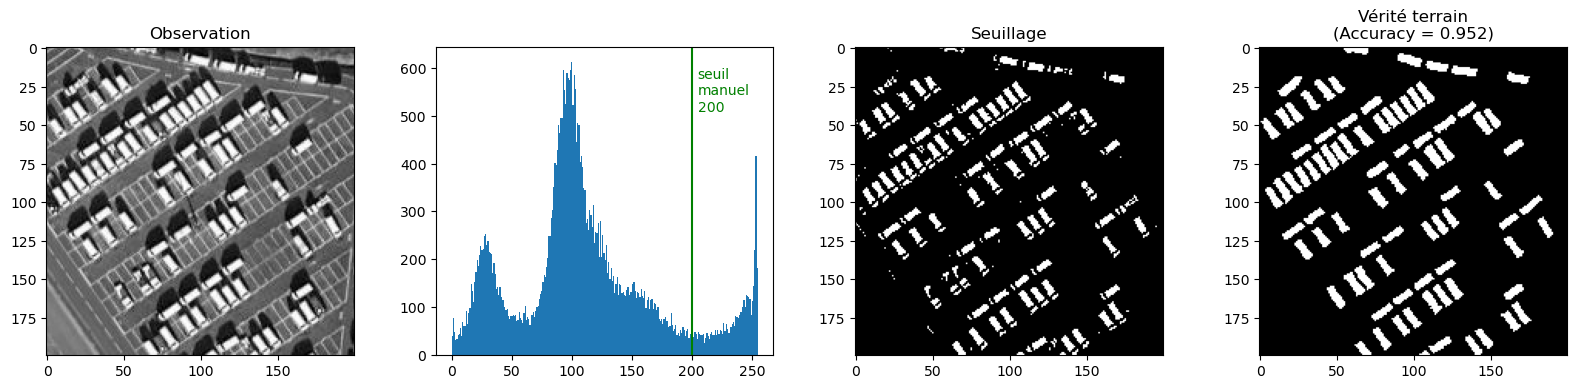

In [3]:
# Image
img = io.imread('parking.png')

# Seuillage
s = 200
seg = 1 * (img > s)

# Affichage
myshow(img, gt, seg, s, f"seuil\nmanuel\n{s}", color="g")

# On conserve cette segmentation
good_seg = seg.copy()

## Segmentation avec la méthode de Otsu

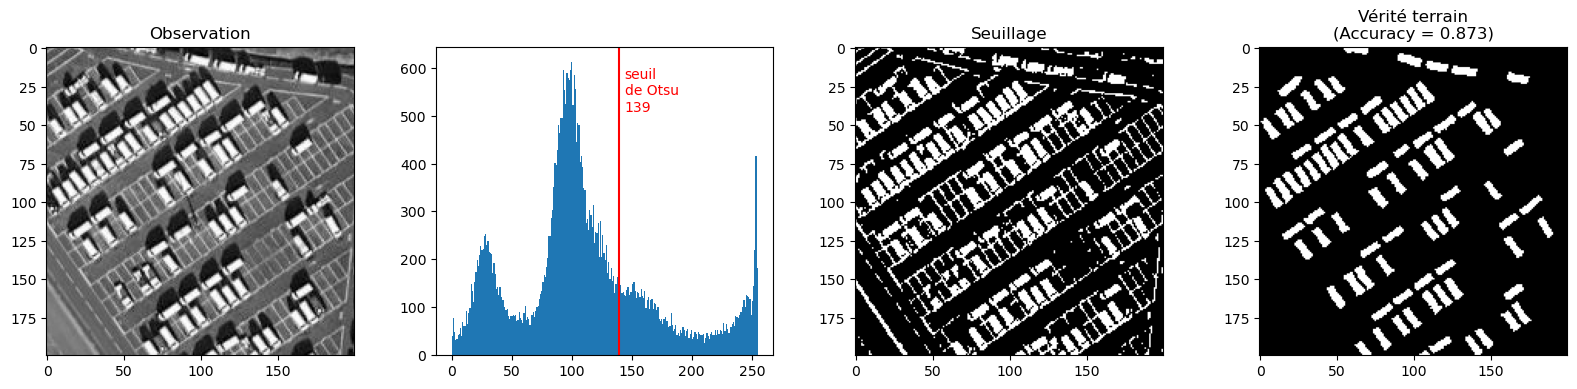

In [4]:
# Image
img = io.imread('parking.png')

# Seuillage
s = threshold_otsu(img)
seg = 1 * (img > s)

# Affichage
myshow(img, gt, seg, s, f"seuil\nde Otsu\n{s}", color="r")

## Dénombrement automatique des véhicules

In [5]:
# Nombre véritable de véhicules
lbl = label(gt)
K = lbl.max()
print(f"La vérité terrain permet de comptabiliser {K} véhicules")

La vérité terrain permet de comptabiliser 79 véhicules


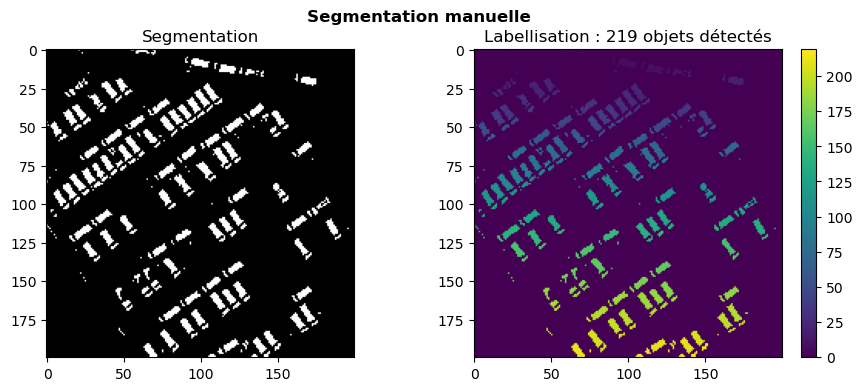

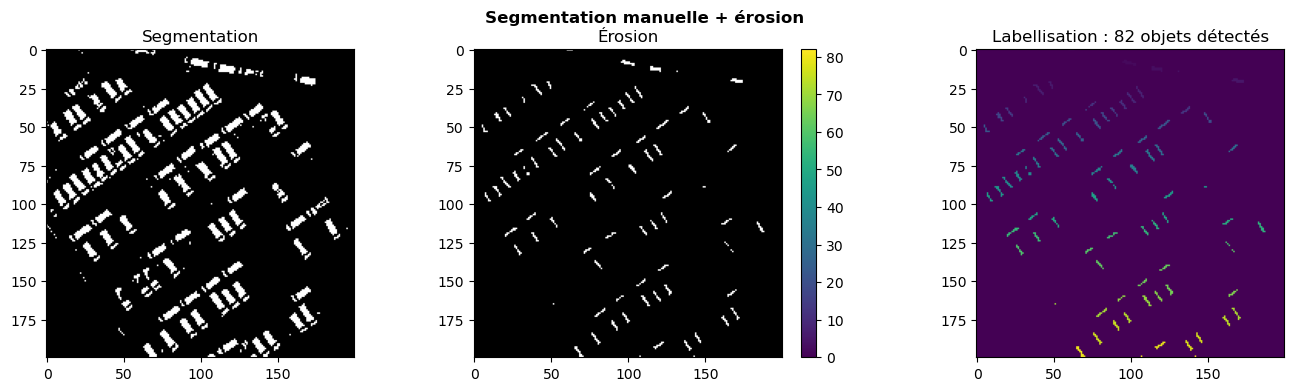

In [6]:
# Segmentation considérée
seg = good_seg.copy()

# Sans érosion
lbl = label(seg)
K = lbl.max()

# Affichage
fig, axs = plt.subplots(1,2,figsize=(11,4))
axs[0].imshow(seg, "gray")
axs[0].set_title(f"Segmentation")
im = axs[1].imshow(lbl)
fig.colorbar(im, ax=axs[1])
axs[1].set_title(f"Labellisation : {K} objets détectés")
fig.suptitle("Segmentation manuelle", fontweight="bold")
plt.show()

# Avec érosion
M = 3
h = np.ones((M,M))
ero = binary_erosion(seg, h)
lbl = label(ero)
K = lbl.max()

# Affichage
fig, axs = plt.subplots(1,3,figsize=(17,4))
axs[0].imshow(seg, "gray")
axs[0].set_title(f"Segmentation")
axs[1].imshow(ero, "gray")
axs[1].set_title(f"Érosion")
im = axs[2].imshow(lbl)
fig.colorbar(im, ax=axs[1])
axs[2].set_title(f"Labellisation : {K} objets détectés")
fig.suptitle("Segmentation manuelle + érosion", fontweight="bold")
plt.show()

## Perspectives

L'érosion est une méthode issue de la **morphologie mathématique**, au même titre que la dilatation, l'ouverture ou la fermeture.
Ces méthodes considèrent une image binaire comme un ensemble d'objets blancs sur un fond noir.
En se fondant sur la théorie des ensembles, la théorie des teillis et la topologie, elle a permis de développer des outils effeicaces et rapides pour améliorer ou simplifier des segmentations binaires.

Néanmoins, pour prendre en compte l'aspect spatial d'une image lors d'une segmentation,
les méthodes vraiment performantes évitent d'effectuer une segmentation pixel par pixel suivie d'un post-traitement.
On peut citer les **méthodes basées région** ou, mieux encore : les **méthodes bayésiennes avec modèles markoviens**.